# Getting started: the three emergence tests on a toy Ising system

Companion notebook to 

> Riedl, C. & Rosas, F.E. (2026). **Claims of emergence in AI should be grounded in information decomposition.**
> *In Advances in Neural Information Processing Systems*, volume 39, 2026.

See [arXiv](https://arxiv.org/abs/XXXX.XXXX).

```bibtex
@inproceedings{riedl2026multi,
  title     = {Claims of emergence in AI should be grounded in information decomposition},
  author    = {Riedl, Christoph and Rosas, Fernando E.},
  booktitle = {Advances in Neural Information Processing Systems},
  year      = {2026},
  volume    = {39}
}
```


**What this notebook does.** It takes a small discrete dynamical system whose statistics are known *exactly*, and runs the three emergence tests of Section 2.2. It then swepts a control parameter that moves the system from independent parts, through an interacting regime, to frozen synchrony. Because everything is exact (no estimator), you can see what each test can and cannot detect before you apply it to real data. A final section adds the estimation layer (sampled trajectories, permutation null, bias correction) so you can see how plug-in estimates drift from the truth.

**How to run.** `pip install -r requirements.txt`, then run all cells. Runtime is well under a minute on a laptop. All code lives in `pid_emergence.py`; this notebook only calls it.

**What this is not.** It is not an estimator benchmark and not a claim about any real system. It is the minimal object on which the three tests can be understood, and a template for applying them to your own lagged joint distribution. The the paper for discussion of details, pitfalls, and reporting practices.

## 1. The three tests

Let $X_t = (X_{1,t},\dots,X_{n,t})$ be the microstate of an $n$-part system, $\ell$ the integration timescale, and $V_t = f(X_t)$ a macro variable. Using the two-source PID of Eq. (1) with a named redundancy measure:

| Test | Statistic | Positive means |
|---|---|---|
| **Emergence capacity** | median over pairs $(i,j)$ of $\mathrm{Syn}\big(X_{i,t}, X_{j,t};\,(X_{i,t+\ell}, X_{j,t+\ell})\big)$ | some pair's joint future is predicted by the pair jointly beyond what either part gives. Order-2 only. No macro needed. |
| **Unique-information criterion** (order $k$) | $\mathrm{Un}^{(k)}(V_t;\,X_{t+\ell}\mid X_t) > 0$; here $k=1$: $\;I(V_t; X_{t+\ell}) - \max_i I(X_{i,t}; X_{t+\ell})$ | the macro predicts the micro future better than any single part. |
| **Practical criterion** | $\Psi_\ell(V) = I(V_t; V_{t+\ell}) - \sum_i I(X_{i,t}; V_{t+\ell})$ (Eq. 4) | the macro's self-predictability exceeds the sum of what the parts say about it. Order-agnostic, but penalised by redundancy. |

One point the implementation makes unavoidable: for a deterministic macro $V_t = f(X_t)$, the unique information against the **full** microstate is identically zero for any non-negative PID, because $I(V_t; X_{t+\ell} \mid X_t) = 0$ and $\mathrm{Un}_V + \mathrm{Syn} = I(V_t; X_{t+\ell}\mid X_t)$. The criterion is only informative at order $k < n$, i.e. against subsets of parts. The notebook checks the identity numerically in Section 5.

## 2. The toy: a kinetic Ising ring

$n$ spins $s_i \in \{-1,+1\}$ on a ring, ferromagnetic coupling $J=1$, no external field, synchronous Glauber dynamics: each spin at $t+1$ is drawn as $+1$ with probability $\sigma\!\big(2\beta\,(s_{i-1}+s_{i+1})\big)$. The inverse temperature $\beta$ is the single control parameter:

- $\beta = 0$: every spin is an independent coin flip at every step. All tests must read zero. (Limiting case.)
- $\beta \to \infty$: spins lock to their neighbours; the ring freezes into all-up or all-down. The parts become clones, which under the paper's *differentiation requirement* (principle i) can only carry redundancy.
- intermediate $\beta$: the interesting regime.

Two macro variables are used throughout:

- **Magnetisation** $M = \sum_i s_i$, the order parameter; a sum over parts, like group error in Section 3.2.
- **Energy** $E = \sum_i [s_i \neq s_{i+1}]$, the number of domain walls; a sum of pairwise XORs. With no external field the dynamics are symmetric under a global spin flip, and $E$ is flip-invariant, so **no single spin carries any information about $E$**. That makes it a built-in example of information that lives only in combinations of parts.

$n$ is odd on purpose: with synchronous updates an even ring is bipartite, the two sublattices decouple, and a period-2 alternating cycle appears; that is an artifact of the update rule, not of the physics we want to illustrate.

In [1]:
import sys, platform, hashlib, datetime
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

import pid_emergence as pe

N_SPINS = 5          # odd, see Section 2
LAG = 1              # synchronous dynamics: one update = one step
SEED = 20261008      # used only by the sampling section
BETAS = np.round(np.arange(0.0, 3.01, 0.1), 2)

def energy(states):
    return (states != np.roll(states, 1, axis=1)).sum(1)

MACROS = {"magnetisation": pe.magnetisation, "energy": energy}

print("python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)
print("pid_emergence.py sha256:", hashlib.sha256(open("pid_emergence.py", "rb").read()).hexdigest()[:16])
print("run date:", datetime.date.today().isoformat())

python 3.12.7 | numpy 1.26.4 | pandas 2.2.3 | matplotlib 3.10.8
pid_emergence.py sha256: b8f6a553b885f87e
run date: 2026-10-20


## 3. One value of $\beta$, in full

Build the system, get the exact stationary lagged joint $p(s_t, s_{t+1})$, and print the full two-source PID for one adjacent and one non-adjacent pair, under the three implemented redundancy measures (MMI, $I_{\min}$, BROJA).

In [2]:
beta_demo = 1.0
states, P = pe.ising_transition_matrix(N_SPINS, beta_demo)
joint = pe.exact_lagged_joint(P, lag=LAG)
print(f"{2**N_SPINS} microstates; transition matrix rows sum to 1: {np.allclose(P.sum(1), 1)}; joint sums to {joint.sum():.6f}")

rows = []
for red in ("mmi", "imin", "broja"):
    cap = pe.emergence_capacity(states, joint, redundancy=red)
    for pair in [(0, 1), (0, 2)]:
        a = cap["pairs"][pair]
        rows.append({"redundancy": red, "pair": pair, "adjacent": pair[1] - pair[0] == 1,
                     **{k: round(v, 4) for k, v in a.items()}})
pd.DataFrame(rows)

32 microstates; transition matrix rows sum to 1: True; joint sums to 1.000000


,redundancy,pair,adjacent,I1,I2,I12,red,un1,un2,syn
0,mmi,"(0, 1)",True,0.5405,0.5405,0.9071,0.5405,0.0000,0.0000,0.3666
1,mmi,"(0, 2)",False,0.2580,0.2580,0.3421,0.2580,0.0000,0.0000,0.0841
2,imin,"(0, 1)",True,0.5405,0.5405,0.9071,0.5405,0.0000,0.0000,0.3666
3,imin,"(0, 2)",False,0.2580,0.2580,0.3421,0.2580,-0.0000,-0.0000,0.0841
4,broja,"(0, 1)",True,0.5405,0.5405,0.9071,0.1799,0.3606,0.3606,0.0060
5,broja,"(0, 2)",False,0.2580,0.2580,0.3421,0.1870,0.0710,0.0710,0.0130


Columns `I1`, `I2` are each part's information about the pair's joint future, `I12` the pair's joint information, and `red / un1 / un2 / syn` the four atoms, which sum to `I12`.

Three things to notice. First, for binary parts with symmetric roles ($I_1 = I_2$) MMI forces both unique atoms to zero by definition and reports everything above the marginal information as synergy: $\mathrm{Syn}_{\text{MMI}} = I_{12} - \max(I_1, I_2) = I(X_j; T \mid X_i)$, a conditional mutual information. Second, MMI and $I_{\min}$ coincide on this system to numerical precision, so reporting both is one measure counted twice. Third, BROJA, which minimises the joint information over all distributions with the same pairwise source–target marginals, gives a different answer: most of what MMI calls synergy becomes *unique* information (under synchronous updates each spin's next state is driven by its neighbours, so a neighbour holds information about it that the spin itself does not), and the synergy that remains is small. The totals $I_1, I_2, I_{12}$ are the same under every measure; the labels of the atoms are not. This is the "report two measures" advice of Table S1 biting on the simplest possible system.

Also note the two pair classes. On a 5-ring every pair is either adjacent, like $(0,1)$, or next-nearest, like $(0,2)$, and by rotation symmetry the ten pairs take only these two values. Keep that in mind when reading the "median over pairs" below.

In [3]:
rows = []
for name, macro in MACROS.items():
    r = pe.run_all_tests(states, joint, macro)
    u = pe.unique_information_criterion(states, joint, macro)
    p = pe.practical_criterion(states, joint, macro)
    rows.append({"macro": name, "capacity Syn (median)": r["capacity_syn"], "capacity Red (median)": r["capacity_red"],
                 "Un1 = I(V;X') - max_i I(X_i;X')": r["un1"], "I(V;X')": u["I_V"], "max_i I(X_i;X')": max(u["I_parts"]),
                 "Psi_l(V)": r["psi"], "I(V;V')": p["I_VV"], "sum_i I(X_i;V')": sum(p["I_parts"])})
pd.DataFrame(rows).set_index("macro").T.round(4)

macro,magnetisation,energy
capacity Syn (median),0.2253,0.2253
capacity Red (median),0.3993,0.3993
Un1 = I(V;X') - max_i I(X_i;X'),0.7487,-0.0684
I(V;X'),1.4667,0.6496
max_i I(X_i;X'),0.7180,0.7180
Psi_l(V),-1.3408,0.6474
I(V;V'),1.4633,0.6474
sum_i I(X_i;V'),2.8040,-0.0000


## 4. Sweep over the control parameter

In [4]:
records = []
for beta in BETAS:
    st, Pb = pe.ising_transition_matrix(N_SPINS, beta)
    Jb = pe.exact_lagged_joint(Pb, lag=LAG)
    cap = pe.emergence_capacity(st, Jb)
    cap_b = pe.emergence_capacity(st, Jb, "broja")
    rec = {"beta": beta, "capacity_syn": cap["syn_median"], "capacity_red": cap["red_median"],
           "capacity_syn_broja": cap_b["syn_median"], "capacity_red_broja": cap_b["red_median"],
           "capacity_un_broja": float(np.median([v["un1"] for v in cap_b["pairs"].values()]))}
    for name, macro in MACROS.items():
        u = pe.unique_information_criterion(st, Jb, macro)
        p = pe.practical_criterion(st, Jb, macro)
        rec[f"un1_{name}"] = u["un1"]
        rec[f"psi_{name}"] = p["psi"]
        rec[f"full_order_{name}"] = u["full_order_conditional"]
        rec[f"sum_parts_{name}"] = sum(p["I_parts"])
    records.append(rec)
sweep = pd.DataFrame(records)
sweep.to_csv("fig/sweep_n5.csv", index=False)
sweep[["beta", "capacity_syn", "capacity_red", "capacity_syn_broja", "capacity_un_broja", "un1_magnetisation", "un1_energy", "psi_magnetisation", "psi_energy"]].round(4)

,beta,capacity_syn,capacity_red,capacity_syn_broja,capacity_un_broja,un1_magnetisation,un1_energy,psi_magnetisation,psi_energy
0,0.0,0.0000,0.0000,0.0000,-0.0000,0.0000,0.0000,0.0000,0.0000
1,0.1,0.0036,0.0036,-0.0000,0.0036,0.0144,-0.0135,-0.0001,0.0007
2,0.2,0.0142,0.0142,-0.0000,0.0142,0.0571,-0.0444,-0.0018,0.0099
3,0.3,0.0313,0.0313,0.0000,0.0313,0.1266,-0.0747,-0.0097,0.0408
4,0.4,0.0544,0.0546,0.0000,0.0544,0.2202,-0.0899,-0.0325,0.1022
5,0.5,0.0831,0.0844,0.0001,0.0830,0.3326,-0.0844,-0.0842,0.1947
6,0.6,0.1164,0.1222,0.0005,0.1159,0.4553,-0.0617,-0.1837,0.3097
7,0.7,0.1520,0.1706,0.0016,0.1504,0.5746,-0.0330,-0.3515,0.4315
8,0.8,0.1856,0.2326,0.0035,0.1821,0.6734,-0.0147,-0.6027,0.5400
9,0.9,0.2117,0.3096,0.0062,0.2055,0.7349,-0.0232,-0.9385,0.6162


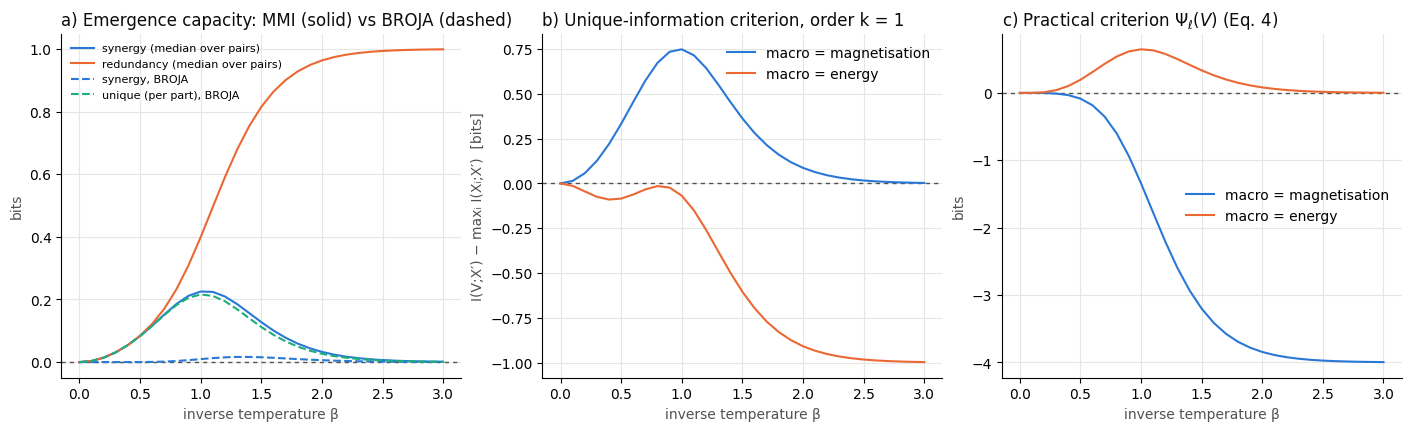

In [5]:
# Palette: first three slots of the validated reference palette (adjacent-pair CVD-safe).
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GRID, INK, MUTED = "#e6e6e3", "#0b0b0b", "#52514e"

def style(ax):
    ax.axhline(0, color=MUTED, lw=1, ls=(0, (3, 3)), zorder=1)
    ax.grid(color=GRID, lw=0.8, zorder=0); ax.set_axisbelow(True)
    for sp in ("top", "right"): ax.spines[sp].set_visible(False)
    ax.set_xlabel("inverse temperature β", color=MUTED)
    ax.set_ylabel("bits", color=MUTED)

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), constrained_layout=True)
for ax in axes: style(ax)

ax = axes[0]
ax.plot(sweep.beta, sweep.capacity_syn, color=BLUE, lw=1.5, label="synergy (median over pairs)")
ax.plot(sweep.beta, sweep.capacity_red, color=ORANGE, lw=1.5, label="redundancy (median over pairs)")
ax.plot(sweep.beta, sweep.capacity_syn_broja, color=BLUE, lw=1.5, ls="--", label="synergy, BROJA")
ax.plot(sweep.beta, sweep.capacity_un_broja, color=AQUA, lw=1.5, ls="--", label="unique (per part), BROJA")
ax.set_title("a) Emergence capacity: MMI (solid) vs BROJA (dashed)", loc="left", color=INK)
ax.legend(frameon=False, loc="upper left", fontsize=8)

ax = axes[1]
ax.plot(sweep.beta, sweep.un1_magnetisation, color=BLUE, lw=1.5, label="macro = magnetisation")
ax.plot(sweep.beta, sweep.un1_energy, color=ORANGE, lw=1.5, label="macro = energy")
ax.set_title("b) Unique-information criterion, order k = 1", loc="left", color=INK)
ax.set_ylabel("I(V;X′) − maxᵢ I(Xᵢ;X′)  [bits]", color=MUTED); ax.legend(frameon=False)

ax = axes[2]
ax.plot(sweep.beta, sweep.psi_magnetisation, color=BLUE, lw=1.5, label="macro = magnetisation")
ax.plot(sweep.beta, sweep.psi_energy, color=ORANGE, lw=1.5, label="macro = energy")
ax.set_title(r"c) Practical criterion $\Psi_\ell(V)$ (Eq. 4)", loc="left", color=INK)
ax.legend(frameon=False)

fig.savefig("fig/ising_emergence_tests.png", dpi=150)
plt.show()

### Reading the figure

- **a) Capacity** under MMI (solid) is zero at $\beta=0$, rises to a peak at intermediate coupling, and collapses back to zero at strong coupling while redundancy saturates at one bit. Two caveats before reading the peak as "synergy". The plotted number is the median over the ten pairs, and on a 5-ring the ten pairs take only two values (five adjacent, five next-nearest; Section 3 shows both), so the median is the midpoint between them, a value no single pair has. And under BROJA (dashed) most of the MMI synergy is relabelled as unique information: with symmetric sources MMI cannot assign unique information at all, whereas here each spin's next state is driven by its neighbours, which BROJA reports as information a neighbour holds uniquely. What survives every measure is the shape: nothing at $\beta=0$, something at intermediate $\beta$, and only redundancy once the spins are clones (the *differentiation requirement*, principle i). Which atom carries the "something" is a property of the redundancy function, not of the system. That is why Table S1 asks for two measures, and why the two have to be able to disagree.
- **c) Practical criterion** depends entirely on the macro. For **magnetisation** it is negative at every $\beta > 0$: each spin individually predicts the future magnetisation, the sum over five parts over-counts, and the redundancy penalty swamps whatever synergy exists. This is the failure mode the paper names ("penalised by redundancy ... can make the score negative even when higher-order synergy exists"). For **energy** the sum term is exactly zero by symmetry (flip-invariant macro, no field), so $\Psi_\ell(E)$ reduces to $I(E_t; E_{t+1})$, which is positive whenever $E$ is autocorrelated. Panel c for energy is therefore **not a detection of synergy**; it shows what $\Psi$ becomes when the redundancy penalty is removed by construction. Same system, same test, opposite sign, and in neither case does the sign by itself say much about emergence: the choice of macro is a modelling decision the theory does not make for you (Table S1, first row).
- **b) Unique-information criterion** at order 1 is positive for magnetisation (the sum beats any single spin at predicting the micro future; a summary statistic over five noisy parts filters noise that one part cannot) and negative for energy at $n = 5$ (a single spin is a better predictor of the whole next microstate than the domain-wall count, which discards where the walls are). The test is one-sided; a negative value says the macro is not a privileged predictor, not that the system lacks emergence. The sign of this test depends on $n$ and on the order $k$, so it is reported, not asserted.

The three tests are three different questions. Agreement is not guaranteed and disagreement is informative.

## 5. Invariants and limiting cases

Only provable properties are asserted (the same checks live in `test_invariants.py`). Empirical regularities, such as where the capacity peak sits, are reported above, not asserted.

In [6]:
checks = []
row0 = sweep.iloc[0]
checks.append(("beta = 0: all three tests are zero (independent parts)",
               max(abs(row0[c]) for c in sweep.columns if c != "beta") < 1e-9))
checks.append(("full-order Un of a deterministic macro is zero at every beta",
               sweep[["full_order_magnetisation", "full_order_energy"]].abs().max().max() < 1e-9))
checks.append(("flip-invariant macro (energy): sum_i I(X_i; E') is zero at every beta",
               sweep["sum_parts_energy"].abs().max() < 1e-9))
ok = True
for beta in (0.3, 1.0, 2.0):
    st, Pb = pe.ising_transition_matrix(N_SPINS, beta)
    for red in ("mmi", "imin", "broja"):
        for a in pe.emergence_capacity(st, pe.exact_lagged_joint(Pb), red)["pairs"].values():
            ok &= all(a[k] > -1e-10 for k in ("red", "un1", "un2", "syn"))
            ok &= abs(a["red"] + a["un1"] + a["un2"] + a["syn"] - a["I12"]) < 1e-10
checks.append(("PID atoms non-negative and sum to I12 (MMI, I_min, BROJA)", ok))
checks.append(("strong coupling: capacity synergy below 0.005 bits at beta = 3",
               sweep.loc[sweep.beta == 3.0, "capacity_syn"].item() < 0.005))
for name, passed in checks:
    print(f"{'PASS' if passed else 'FAIL'}  {name}")

PASS  beta = 0: all three tests are zero (independent parts)
PASS  full-order Un of a deterministic macro is zero at every beta
PASS  flip-invariant macro (energy): sum_i I(X_i; E') is zero at every beta
PASS  PID atoms non-negative and sum to I12 (MMI, I_min, BROJA)
PASS  strong coupling: capacity synergy below 0.005 bits at beta = 3


## 6. The estimation layer: sampled trajectories, permutation null, bias correction

Real data give you a trajectory, not a transition matrix. Here we simulate trajectories of length $T$, estimate the joint by plug-in counts, and correct against a null that permutes the pairing between $s_t$ and $s_{t+1}$ (destroys all predictive information, keeps same-time marginals). Raw, null mean, and bias-corrected (BC) values are compared with the exact ones from Section 4. Plug-in mutual information is positively biased, so raw values sit above the truth at small $T$.

The null used here is a *full* shuffle of the pairing, chosen for illustration. It is not the only choice and not always the right one: a block shuffle preserves autocorrelation within each part, a functional null preserves a fitted model, and the paper (Table S1 and Section 3.2) discusses when each applies. The null should be guided by theory and tailored to where bias is likely to come from in your data; on an autocorrelated time series a full shuffle is usually too permissive.

In [7]:
rows = []
for beta in (0.3, 1.0, 2.0):
    st, Pb = pe.ising_transition_matrix(N_SPINS, beta)
    exact = pe.run_all_tests(st, pe.exact_lagged_joint(Pb), pe.magnetisation)
    for T in (1000, 10000, 100000):
        est = pe.sampled_tests(st, Pb, T=T, seed=SEED, lag=LAG, n_null=50)
        for k in ("capacity_syn", "psi"):
            rows.append({"beta": beta, "T": T, "statistic": k, "exact": exact[k], "raw": est["raw"][k],
                         "null_mean": est["null_mean"][k], "null_sd": est["null_sd"][k], "BC": est["bc"][k]})
est_df = pd.DataFrame(rows)
est_df.to_csv("fig/estimation_n5.csv", index=False)
est_df.round(4)

,beta,T,statistic,exact,raw,null_mean,null_sd,BC
0,0.3,1000,capacity_syn,0.0313,0.0300,0.0030,0.0006,0.0270
1,0.3,1000,psi,-0.0097,-0.0011,-0.0011,0.0060,-0.0000
2,0.3,10000,capacity_syn,0.0313,0.0280,0.0003,0.0001,0.0277
3,0.3,10000,psi,-0.0097,-0.0114,0.0000,0.0006,-0.0114
4,0.3,100000,capacity_syn,0.0313,0.0306,0.0000,0.0000,0.0306
5,0.3,100000,psi,-0.0097,-0.0107,-0.0000,0.0001,-0.0107
6,1.0,1000,capacity_syn,0.2253,0.1950,0.0032,0.0009,0.1919
7,1.0,1000,psi,-1.3408,-0.9965,-0.0015,0.0073,-0.9950
8,1.0,10000,capacity_syn,0.2253,0.2205,0.0003,0.0001,0.2201
9,1.0,10000,psi,-1.3408,-1.3887,-0.0001,0.0007,-1.3886


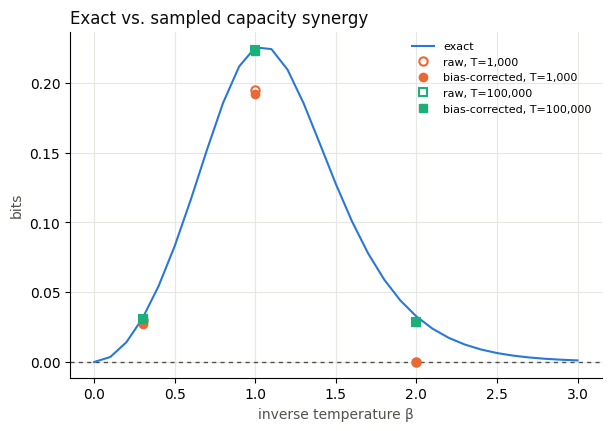

In [8]:
sub = est_df[est_df.statistic == "capacity_syn"]
fig_d, ax = plt.subplots(figsize=(6, 4.2), constrained_layout=True)
style(ax)
ax.plot(sweep.beta, sweep.capacity_syn, color=BLUE, lw=1.5, label="exact")
for T, col, mk in ((1000, ORANGE, "o"), (100000, AQUA, "s")):
    d = sub[sub["T"] == T]
    ax.plot(d.beta, d.raw, ls="none", marker=mk, ms=6, mfc="none", mec=col, mew=1.5, label=f"raw, T={T:,}")
    ax.plot(d.beta, d.BC, ls="none", marker=mk, ms=6, color=col, label=f"bias-corrected, T={T:,}")
ax.set_title("Exact vs. sampled capacity synergy", loc="left", color=INK)
ax.legend(frameon=False, fontsize=8)
fig_d.savefig("fig/exact_vs_sampled.png", dpi=150)
plt.show()

Two different errors show up in the table and in the figure, and only one of them is what bias correction addresses.

- **Plug-in bias is small here.** The null mean is at most a few thousandths of a bit, because 32 microstates is a tiny alphabet relative to $T$. Raw and bias-corrected values nearly coincide. On real data the alphabet is usually far larger relative to $T$ and this term dominates; that is why Table S1 asks for sample-size sensitivity.
- **Mixing is the dominant error on this system.** At $\beta = 2$ the chain sits in one attractor for long stretches. A 1,000-step trajectory never leaves it, every variable looks constant, and all tests read zero, raw and corrected alike, against an exact capacity synergy of 0.033 bits and an exact $\Psi_\ell(V)$ of $-3.85$ bits. At $\beta = 1$ and $T = 1000$ the raw value sits *below* the exact one for the same reason. Bias correction cannot repair a trajectory that has not sampled the stationary distribution. **A bias-corrected zero is not evidence of absence.** The analogue on real data is a recording shorter than the slowest relevant dynamics.

At $T = 100{,}000$ raw and exact agree to within about 0.005 bits for capacity synergy and 0.02 bits for $\Psi_\ell(V)$ at every $\beta$ shown.

## 7. Applying the tests to your own system

Everything above runs on one object: an $S \times S$ array `joint[s, s']` $= p(s_t = s,\; s_{t+\ell} = s')$ over enumerated microstates, plus a `states` array giving each part's value in each microstate. To use your data:

```python
# 1. Discretise each part and enumerate the microstates that occur.
#    states: (S, n) array; row s = value of each part in microstate s.
# 2. Map your trajectory to microstate indices a[t]; form lagged pairs (a[t], a[t+lag]).
joint = pe.empirical_joint(a[:-lag], a[lag:], S)
# 3. Define your macro as a function of `states`, then:
pe.run_all_tests(states, joint, macro=my_macro, redundancy="mmi")   # or "broja" (binary parts), "imin"
# 4. Build a permutation null the same way (see pe.sampled_tests) and subtract.
```

Things this toy does not cover, which you must decide and should report (see Practical Guidlines in Table S1 and Reporting Box S1): what counts as a part, the timescale $\ell$, how continuous signals were discretised, the redundancy measure and a second one for robustness, the estimator and its bias correction, and a null that preserves what your data's dependence structure requires (e.g., block-shuffled for autocorrelated time series).